# Bilfinger 2025 standard state-of-health charging recordings

This notebook lists the files in the mediaTUM release, opens one Tesla Model Y charging recording as released, and plots its pack voltage. It makes no diagnosis.

## 1. Released units

This step lists what `systems('bilfinger2025')` reports for the release.

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import pandas as pd

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / 'fielddata').exists())
sys.path.insert(0, str(ROOT))
from fielddata import load, systems

released = systems('bilfinger2025')
display(released)

,unit,kind,vehicle,format,member,bytes
0,Cupra_Born_204_JB_8A_CEE7_CS_2024,vehicle,Cupra 204,feather,m1765567/data/Cupra/Cupra_Born_204_JB_8A_CEE7_...,15132458
1,Cupra_Born_213_JB_8A_CEE7_CS_2024,vehicle,Cupra 213,feather,m1765567/data/Cupra/Cupra_Born_213_JB_8A_CEE7_...,12690058
2,Cupra_Born_288_JB_8A_CEE7_CS_2024,vehicle,Cupra 288,feather,m1765567/data/Cupra/Cupra_Born_288_JB_8A_CEE7_...,12171442
3,Cupra_Born_349_JB_8A_CEE7_CS_2024,vehicle,Cupra 349,feather,m1765567/data/Cupra/Cupra_Born_349_JB_8A_CEE7_...,13200642
4,Cupra_Born_397_JB_8A_CEE7_CS_2024,vehicle,Cupra 397,feather,m1765567/data/Cupra/Cupra_Born_397_JB_8A_CEE7_...,11301618
5,Porsche_Taycan_JB_10A_CEE7_AMS_2024,vehicle,Porsche Taycan (AMS),feather,m1765567/data/Taycan/Porsche_Taycan_JB_10A_CEE...,70225882
6,Porsche_Taycan_JB_10A_CEE7_FTM_2023,vehicle,Porsche Taycan (FTM),feather,m1765567/data/Taycan/Porsche_Taycan_JB_10A_CEE...,3979290
7,Tesla_Model_3_JB_6A_CEE7_FTM_2021,vehicle,Tesla Model 3 SR+,feather,m1765567/data/Tesla/Tesla_Model_3_JB_6A_CEE7_F...,18454434
8,Tesla_Model_3_JB_6A_CEE7_FTM_2025,vehicle,Tesla Model 3 SR+,feather,m1765567/data/Tesla/Tesla_Model_3_JB_6A_CEE7_F...,4456274
9,Tesla_Model_Y_JB_8A_CEE7_MI_2025,vehicle,Tesla Model Y (MI),feather,m1765567/data/Tesla/Tesla_Model_Y_JB_8A_CEE7_M...,8649906


Each row is one released file, with the vehicle it belongs to: two VW ID.3 (the second, file code GB, has a defective cell), five CUPRA Born, a Tesla Model 3, two Porsche Taycan and two Tesla Model Y. The first ID.3, the Model 3 and the five CUPRA Born are vehicles of bilfinger2024 and bilfinger2026 and count once in the collection totals. The four VW cell files are laboratory reference curves, not field units.

## 2. One unit as released

This step loads one unit with the default `clean=False`, so every value is as released.

In [2]:
frame = load('bilfinger2025', unit='Tesla_Model_Y_JB_8A_CEE7_MI_2025')
print(frame.shape)
display(frame.head())

(14766, 136)


,index,UnixTimeSeconds528,ChargeHoursRemaining132,U,RawBattCurrent132,I,BattBeginningOfLifeEnergy292,SOCmax292,SOC,SOCUI292,...,UI_Range,UI_SOC,UI_uSOE,UI_ratedWHpM,time_ms,time_s,time_min,time_h,Q,E
6,875,1.738601e+09,2775.0,291.931111,-5.255618,4.937079,78.8,3.4,2.7,1.8,...,0.0,17,101,1020,60000.0,60.0,1.000000,0.016667,0.080846,23.610798
7,876,1.738601e+09,2775.0,292.033409,-5.200000,4.900000,78.8,3.4,2.7,1.8,...,0.0,17,101,1020,70000.0,70.0,1.166667,0.019444,0.094508,27.607743
8,877,1.738601e+09,2775.0,292.229412,-4.732813,5.100000,78.8,3.4,2.7,1.8,...,0.0,17,101,1020,80000.0,80.0,1.333333,0.022222,0.108397,31.671929
9,878,1.738601e+09,2775.0,292.334667,-5.633168,5.166337,78.8,3.4,2.7,1.8,...,0.0,17,101,1020,90000.0,90.0,1.500000,0.025000,0.122656,35.845749
10,879,1.738601e+09,2775.0,292.473708,-4.930693,5.200000,78.8,3.4,2.7,1.8,...,0.0,17,101,1020,100000.0,100.0,1.666667,0.027778,0.137053,40.062525


The recording is one slow AC charge of a Tesla Model Y. Column order differs between files, so columns are selected by name.

## 3. Signal ranges

This step summarises a few signals of the loaded unit.

In [3]:
display(frame[['U', 'I', 'SOC']].describe().T)

,count,mean,std,min,25%,50%,75%,max
U,14766.0,363.608589,24.613124,291.931111,344.934800,363.984455,387.333564,402.8001
I,14766.0,4.569433,0.355611,2.200000,4.298274,4.523856,4.815125,5.8000
SOC,14766.0,52.365743,28.938165,2.700000,26.700000,52.700000,77.875000,100.0000


These ranges are raw values as released, before any cleaning. The schema file next to the loader lists units and any sentinel codes.

## 4. A first look

This step plots one signal to show the shape of the data.

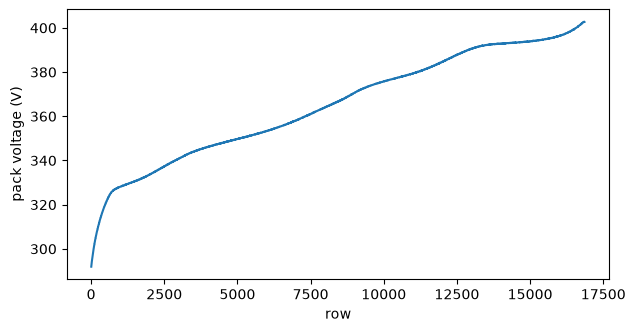

In [4]:
ax = frame['U'].plot(legend=False, figsize=(7, 3.5))
ax.set_xlabel('row')
ax.set_ylabel('pack voltage (V)')
plt.show()

Pack voltage rises through the slow charge, the measurement the paper proposes as a standard.